In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
import sys
!{sys.executable} -m pip install openpyxl

In [7]:
import pandas as pd

In [8]:
excel_file = pd.ExcelFile("landslide_report.xlsx")

print(excel_file.sheet_names)

['Sheet1', 'Sheet2', 'Sheet3', 'Text']


In [9]:
for sheet in excel_file.sheet_names:
    data = pd.read_excel("landslide_report.xlsx", sheet_name=sheet, header=None)
    
    print("\n==============================")
    print("SHEET:", sheet)
    print("SHAPE:", data.shape)
    print("==============================")
    print(data.head(10))


SHEET: Sheet1
SHAPE: (22809, 21)
       0   1                       2   3      4    5           6   7   \
0  Sl.No. NaN                Slide_No NaN  State  NaN    District NaN   
1       1 NaN    ASM/HKN/83D07/2020/2 NaN  Assam  NaN  Hailakandi NaN   
2       2 NaN     AS/HKN/83D11/2020/1 NaN  Assam  NaN  Hailakandi NaN   
3       3 NaN     AS/HKN/83D10/2020/6 NaN  Assam  NaN  Hailakandi NaN   
4       4 NaN     AS/HKN/83D11/2020/4 NaN  Assam  NaN  Hailakandi NaN   
5       5 NaN     AS/KRJ/83D07/2020/1 NaN  Assam  NaN   Karimganj NaN   
6       6 NaN     AS/HKN/83D11/2020/3 NaN  Assam  NaN  Hailakandi NaN   
7       7 NaN     AS/HKN/83D11/2020/2 NaN  Assam  NaN  Hailakandi NaN   
8       8 NaN  ASM/HLKD/83D10/2016/58 NaN  Assam  NaN  Hailakandi NaN   
9       9 NaN     AS/HKN/83D07/2020/1 NaN  Assam  NaN  Hailakandi NaN   

                       8    9   ...   11         12  13         14  15  \
0              Slide_Name  NaN  ...  NaN   Latitude NaN  Longitude NaN   
1          Kuk

In [10]:
for sheet in excel_file.sheet_names:
    data = pd.read_excel("landslide_report.xlsx", sheet_name=sheet, header=None)
    print(sheet, ":", data.shape)

Sheet1 : (22809, 21)
Sheet2 : (4, 3)
Sheet3 : (13441, 21)
Text : (620, 1)


In [11]:
for sheet in excel_file.sheet_names:
    data = pd.read_excel("landslide_report.xlsx", sheet_name=sheet, header=None)
    print("\n", sheet)
    print(data.iloc[:5, :].to_string(index=False, header=False))


 Sheet1
Sl.No. NaN             Slide_No NaN State NaN   District NaN        Slide_Name NaN  NH_SH_Location NaN Latitude NaN Longitude NaN Material Involved NaN   Movement NaN History
     1 NaN ASM/HKN/83D07/2020/2 NaN Assam NaN Hailakandi NaN    Kukinala slide NaN        Kukinala NaN    24.27 NaN      92.5 NaN            Debris NaN Type Slide NaN     NaN
     2 NaN  AS/HKN/83D11/2020/1 NaN Assam NaN Hailakandi NaN Jalnachaura slide NaN     Jalnachaura NaN    24.31 NaN     92.56 NaN            Debris NaN      Slide NaN     NaN
     3 NaN  AS/HKN/83D10/2020/6 NaN Assam NaN Hailakandi NaN   Nandagram slide NaN Nandagram Pt. I NaN    24.32 NaN     92.51 NaN            Debris NaN      Slide NaN     NaN
     4 NaN  AS/HKN/83D11/2020/4 NaN Assam NaN Hailakandi NaN     Nishkar slide NaN         Mahapur NaN    24.43 NaN     92.55 NaN            Debris NaN      Slide NaN     NaN

 Sheet2
road slide 1 NaN village road (NH 306A)
road slide 2 NaN village road (NH 306A)
         NaN NaN           

In [12]:
columns = [
    "Sl_No",
    "Slide_No",
    "State",
    "District",
    "Slide_Name",
    "NH_SH_Location",
    "Latitude",
    "Longitude",
    "Material_Involved",
    "Movement_Type",
    "History"
]

sheet1 = pd.read_excel(
    "landslide_report.xlsx",
    sheet_name="Sheet1",
    header=None
)

sheet3 = pd.read_excel(
    "landslide_report.xlsx",
    sheet_name="Sheet3",
    header=None
)

sheet1 = sheet1.iloc[:, ::2]
sheet3 = sheet3.iloc[:, ::2]

sheet1.columns = columns
sheet3.columns = columns

sheet1 = sheet1.iloc[1:]
sheet3 = sheet3.iloc[1:]

gsi = pd.concat([sheet1, sheet3], ignore_index=True)

print("Total records:", len(gsi))
print(gsi.head())

Total records: 36248
  Sl_No              Slide_No  State    District         Slide_Name  \
0     1  ASM/HKN/83D07/2020/2  Assam  Hailakandi     Kukinala slide   
1     2   AS/HKN/83D11/2020/1  Assam  Hailakandi  Jalnachaura slide   
2     3   AS/HKN/83D10/2020/6  Assam  Hailakandi    Nandagram slide   
3     4   AS/HKN/83D11/2020/4  Assam  Hailakandi      Nishkar slide   
4     5   AS/KRJ/83D07/2020/1  Assam   Karimganj  Paglacherra slide   

    NH_SH_Location Latitude Longitude Material_Involved Movement_Type History  
0         Kukinala    24.27      92.5            Debris    Type Slide     NaN  
1      Jalnachaura    24.31     92.56            Debris         Slide     NaN  
2  Nandagram Pt. I    24.32     92.51            Debris         Slide     NaN  
3          Mahapur    24.43     92.55            Debris         Slide     NaN  
4  PaglacherraPunj    24.44      92.5              Rock         Slide     NaN  


In [13]:
gsi["Latitude"] = pd.to_numeric(gsi["Latitude"], errors="coerce")
gsi["Longitude"] = pd.to_numeric(gsi["Longitude"], errors="coerce")

print(gsi[["Latitude", "Longitude"]].isnull().sum())

Latitude     202
Longitude    203
dtype: int64


In [14]:
print(gsi[["Latitude", "Longitude"]].describe())

           Latitude     Longitude
count  36046.000000  36045.000000
mean      25.084216     82.575224
std        7.298142      7.645334
min        8.490000     72.809500
25%       23.225561     76.670532
50%       27.021116     78.339167
75%       30.780674     92.287167
max       34.758333     96.617190


In [15]:
gsi = gsi.dropna(subset=["Latitude", "Longitude"])

print("Records with coordinates:", len(gsi))

Records with coordinates: 36045


In [16]:
gsi = gsi.drop_duplicates(subset=["Latitude", "Longitude"])

print("Records after removing duplicates:", len(gsi))

Records after removing duplicates: 33898


In [17]:
gsi["Landslide"] = 1

In [18]:
print(gsi["Landslide"].value_counts())

Landslide
1    33898
Name: count, dtype: int64


In [19]:
gsi.to_csv("gsi_landslides_clean.csv", index=False)

print("CSV file created successfully")

CSV file created successfully


In [20]:
print("Total records:", len(gsi))
print(gsi[["Latitude", "Longitude"]].describe())
print(gsi["Landslide"].value_counts())

Total records: 33898
           Latitude     Longitude
count  33898.000000  33898.000000
mean      25.092440     82.701112
std        7.235170      7.639628
min        8.490000     72.809500
25%       23.316258     76.767930
50%       27.020029     78.523319
75%       30.683312     92.357017
max       34.758333     96.617190
Landslide
1    33898
Name: count, dtype: int64


In [21]:
import numpy as np

np.random.seed(42)

min_lat = gsi["Latitude"].min()
max_lat = gsi["Latitude"].max()
min_lon = gsi["Longitude"].min()
max_lon = gsi["Longitude"].max()

negative_samples = []

while len(negative_samples) < len(gsi):
    lat = np.random.uniform(min_lat, max_lat)
    lon = np.random.uniform(min_lon, max_lon)

    distance = ((gsi["Latitude"] - lat) ** 2 + 
                (gsi["Longitude"] - lon) ** 2) ** 0.5

    if distance.min() > 0.05:
        negative_samples.append([lat, lon])

negative = pd.DataFrame(
    negative_samples,
    columns=["Latitude", "Longitude"]
)

negative["Landslide"] = 0

print("Positive samples:", len(gsi))
print("Negative samples:", len(negative))

Positive samples: 33898
Negative samples: 33898


In [22]:
positive = gsi[["Latitude", "Longitude", "Landslide"]].copy()

negative = negative[["Latitude", "Longitude", "Landslide"]].copy()

data = pd.concat([positive, negative], ignore_index=True)

data = data.sample(frac=1, random_state=42).reset_index(drop=True)

print(data.shape)
print(data["Landslide"].value_counts())

(67796, 3)
Landslide
0    33898
1    33898
Name: count, dtype: int64


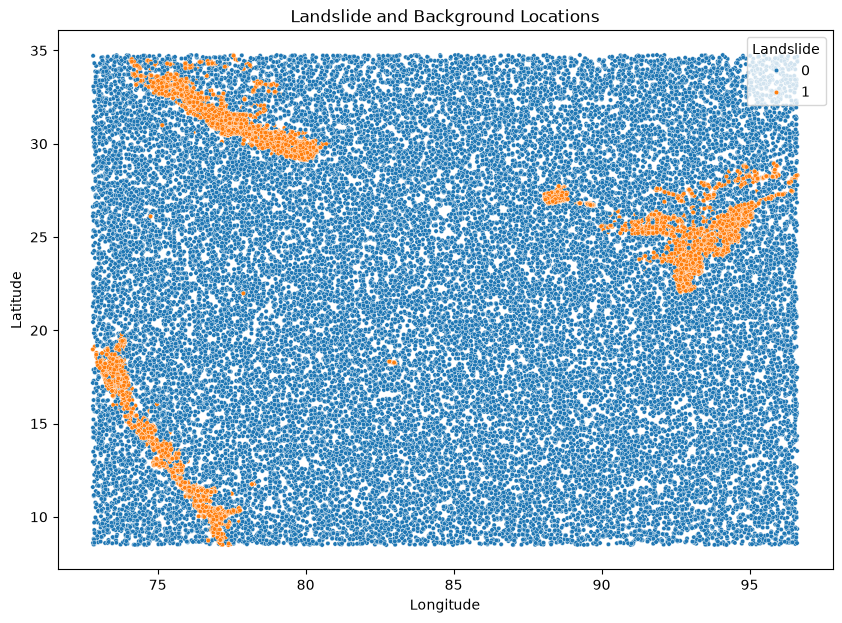

In [23]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=data,
    x="Longitude",
    y="Latitude",
    hue="Landslide",
    s=10
)

plt.title("Landslide and Background Locations")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

In [24]:
import pandas as pd
import numpy as np

data = pd.read_csv("gsi_landslides_clean.csv")

data["Lat_Tile"] = np.floor(data["Latitude"]).astype(int)
data["Lon_Tile"] = np.floor(data["Longitude"]).astype(int)

tiles = data[["Lat_Tile", "Lon_Tile"]].drop_duplicates()

print("Number of required tiles:", len(tiles))
print(tiles.head(20))


Number of required tiles: 94
      Lat_Tile  Lon_Tile
0           24        92
27          24        93
62          25        92
63          25        93
320         25        91
383         26        90
384         26        92
408         26        91
409         26        93
441         26        94
783         23        93
813         26        95
833         27        92
835         27        95
836         27        93
1005        27        96
1122        27        91
1150        28        95
1203        27        94
1350        28        94


In [25]:
def srtm_tile_name(lat, lon):
    lat_dir = "N" if lat >= 0 else "S"
    lon_dir = "E" if lon >= 0 else "W"

    lat_num = abs(int(np.floor(lat)))
    lon_num = abs(int(np.floor(lon)))

    return f"SRTM1{lat_dir}{lat_num:02d}{lon_dir}{lon_num:03d}V3"

tiles["Tile_Name"] = tiles.apply(
    lambda row: srtm_tile_name(row["Lat_Tile"], row["Lon_Tile"]),
    axis=1
)

print(tiles["Tile_Name"].to_string(index=False))

SRTM1N24E092V3
SRTM1N24E093V3
SRTM1N25E092V3
SRTM1N25E093V3
SRTM1N25E091V3
SRTM1N26E090V3
SRTM1N26E092V3
SRTM1N26E091V3
SRTM1N26E093V3
SRTM1N26E094V3
SRTM1N23E093V3
SRTM1N26E095V3
SRTM1N27E092V3
SRTM1N27E095V3
SRTM1N27E093V3
SRTM1N27E096V3
SRTM1N27E091V3
SRTM1N28E095V3
SRTM1N27E094V3
SRTM1N28E094V3
SRTM1N28E096V3
SRTM1N18E083V3
SRTM1N18E082V3
SRTM1N30E077V3
SRTM1N30E079V3
SRTM1N30E076V3
SRTM1N31E077V3
SRTM1N31E076V3
SRTM1N31E078V3
SRTM1N31E075V3
SRTM1N32E075V3
SRTM1N32E076V3
SRTM1N32E077V3
SRTM1N32E078V3
SRTM1N30E075V3
SRTM1N32E074V3
SRTM1N33E075V3
SRTM1N33E074V3
SRTM1N34E074V3
SRTM1N34E075V3
SRTM1N33E076V3
SRTM1N34E077V3
SRTM1N34E078V3
SRTM1N12E075V3
SRTM1N12E074V3
SRTM1N13E075V3
SRTM1N13E074V3
SRTM1N14E074V3
SRTM1N14E075V3
SRTM1N15E074V3
SRTM1N12E076V3
SRTM1N11E076V3
SRTM1N08E077V3
SRTM1N08E076V3
SRTM1N09E077V3
SRTM1N09E076V3
SRTM1N10E076V3
SRTM1N10E077V3
SRTM1N11E075V3
SRTM1N15E073V3
SRTM1N16E073V3
SRTM1N16E074V3
SRTM1N17E073V3
SRTM1N17E074V3
SRTM1N18E073V3
SRTM1N18E072V3
SRTM1N19E0

In [26]:
import os

dem_folder = r"C:\Users\workr\landslide Data\Slope data"

files = [f for f in os.listdir(dem_folder) if f.lower().endswith(".tif")]

print("Number of DEM files:", len(files))
print("\nFirst 10 files:")
for f in files[:10]:
    print(f)

Number of DEM files: 94

First 10 files:
n08_e076_1arc_v3.tif
n08_e077_1arc_v3.tif
n09_e076_1arc_v3.tif
n09_e077_1arc_v3.tif
n10_e076_1arc_v3.tif
n10_e077_1arc_v3.tif
n11_e075_1arc_v3.tif
n11_e076_1arc_v3.tif
n11_e077_1arc_v3.tif
n11_e078_1arc_v3.tif


In [27]:
import sys
!{sys.executable} -m pip install rasterio

In [28]:
import rasterio
print(rasterio.__version__)

1.5.1


In [29]:
import rasterio
import os

dem_folder = r"C:\Users\workr\landslide Data\Slope data"
test_file = os.path.join(dem_folder, "n08_e076_1arc_v3.tif")

with rasterio.open(test_file) as src:
    print("CRS:", src.crs)
    print("Width:", src.width)
    print("Height:", src.height)
    print("Resolution:", src.res)
    print("Bounds:", src.bounds)

CRS: EPSG:4326
Width: 3601
Height: 3601
Resolution: (0.0002777777777777778, 0.0002777777777777778)
Bounds: BoundingBox(left=75.99986111111112, bottom=7.9998611111111115, right=77.0001388888889, top=9.00013888888889)


In [30]:
import pandas as pd

data = pd.read_csv("gsi_landslides_clean.csv")

print("Rows:", len(data))
print("Columns:")
print(data.columns.tolist())
print(data.head())

Rows: 33898
Columns:
['Sl_No', 'Slide_No', 'State', 'District', 'Slide_Name', 'NH_SH_Location', 'Latitude', 'Longitude', 'Material_Involved', 'Movement_Type', 'History', 'Landslide']
   Sl_No              Slide_No  State    District         Slide_Name  \
0      1  ASM/HKN/83D07/2020/2  Assam  Hailakandi     Kukinala slide   
1      2   AS/HKN/83D11/2020/1  Assam  Hailakandi  Jalnachaura slide   
2      3   AS/HKN/83D10/2020/6  Assam  Hailakandi    Nandagram slide   
3      4   AS/HKN/83D11/2020/4  Assam  Hailakandi      Nishkar slide   
4      5   AS/KRJ/83D07/2020/1  Assam   Karimganj  Paglacherra slide   

    NH_SH_Location  Latitude  Longitude Material_Involved Movement_Type  \
0         Kukinala     24.27      92.50            Debris    Type Slide   
1      Jalnachaura     24.31      92.56            Debris         Slide   
2  Nandagram Pt. I     24.32      92.51            Debris         Slide   
3          Mahapur     24.43      92.55            Debris         Slide   
4  Paglac

In [31]:
import os

for file in os.listdir("."):
    if file.endswith(".csv"):
        print(file)

gsi_landslides_clean.csv
landslide_elevation_data.csv
landslide_hydrology_data.csv
landslide_landcover_data.csv
landslide_rainfall_data.csv
landslide_soil_data.csv
landslide_terrain_data.csv
landslide_training_data.csv


In [32]:
import pandas as pd
import numpy as np

gsi = pd.read_csv("gsi_landslides_clean.csv")

np.random.seed(42)

positive = gsi[["Latitude", "Longitude", "Landslide"]].copy()

min_lat = positive["Latitude"].min()
max_lat = positive["Latitude"].max()
min_lon = positive["Longitude"].min()
max_lon = positive["Longitude"].max()

negative_samples = []

while len(negative_samples) < len(positive):
    lat = np.random.uniform(min_lat, max_lat)
    lon = np.random.uniform(min_lon, max_lon)

    distance = np.sqrt(
        (positive["Latitude"].values - lat) ** 2 +
        (positive["Longitude"].values - lon) ** 2
    )

    if distance.min() > 0.05:
        negative_samples.append([lat, lon, 0])

negative = pd.DataFrame(
    negative_samples,
    columns=["Latitude", "Longitude", "Landslide"]
)

data = pd.concat([positive, negative], ignore_index=True)
data = data.sample(frac=1, random_state=42).reset_index(drop=True)

print("Total rows:", len(data))
print(data["Landslide"].value_counts())
print(data.head())


Total rows: 67796
Landslide
0    33898
1    33898
Name: count, dtype: int64
    Latitude  Longitude  Landslide
0  14.870720  87.739860          0
1  23.032444  92.705917          1
2  30.864601  76.999161          1
3  19.387355  91.090495          0
4  29.339634  91.503366          0


In [33]:
data.to_csv("landslide_training_data.csv", index=False)

print("Saved successfully")
print("Rows:", len(data))

Saved successfully
Rows: 67796


In [34]:
import pandas as pd
import rasterio
import os
import math

data = pd.read_csv("landslide_training_data.csv")

dem_folder = r"C:\Users\workr\landslide Data\Slope data"

data["Elevation"] = None

for i in range(len(data)):
    lat = data.loc[i, "Latitude"]
    lon = data.loc[i, "Longitude"]

    lat_tile = math.floor(lat)
    lon_tile = math.floor(lon)

    if lat_tile >= 0:
        lat_name = f"n{lat_tile:02d}"
    else:
        lat_name = f"s{abs(lat_tile):02d}"

    if lon_tile >= 0:
        lon_name = f"e{lon_tile:03d}"
    else:
        lon_name = f"w{abs(lon_tile):03d}"

    filename = f"{lat_name}_{lon_name}_1arc_v3.tif"
    filepath = os.path.join(dem_folder, filename)

    if os.path.exists(filepath):
        with rasterio.open(filepath) as src:
            value = list(src.sample([(lon, lat)]))[0][0]
            data.loc[i, "Elevation"] = value

print("Elevation extraction completed")
print(data[["Latitude", "Longitude", "Elevation", "Landslide"]].head())
print("Missing elevation:", data["Elevation"].isna().sum())

Elevation extraction completed
    Latitude  Longitude Elevation  Landslide
0  14.870720  87.739860      None          0
1  23.032444  92.705917       706          1
2  30.864601  76.999161      1126          1
3  19.387355  91.090495      None          0
4  29.339634  91.503366      None          0
Missing elevation: 30198


In [35]:
print("Missing elevation by class:")
print(data.groupby("Landslide")["Elevation"].apply(lambda x: x.isna().sum()))

print("\nAvailable elevation by class:")
print(data.groupby("Landslide")["Elevation"].apply(lambda x: x.notna().sum()))

Missing elevation by class:
Landslide
0    30198
1        0
Name: Elevation, dtype: int64

Available elevation by class:
Landslide
0     3700
1    33898
Name: Elevation, dtype: int64


In [36]:
import pandas as pd
import numpy as np
import os
import math

gsi = pd.read_csv("gsi_landslides_clean.csv")

positive = gsi[["Latitude", "Longitude", "Landslide"]].copy()

dem_folder = r"C:\Users\workr\landslide Data\Slope data"

dem_files = [f for f in os.listdir(dem_folder) if f.lower().endswith(".tif")]

tiles = []

for file in dem_files:
    name = file.lower()

    lat = int(name[1:3])
    lon = int(name[5:8])

    if name[0] == "s":
        lat = -lat

    if name[4] == "w":
        lon = -lon

    tiles.append((lat, lon))

np.random.seed(42)

negative_samples = []

while len(negative_samples) < len(positive):

    lat_tile, lon_tile = tiles[np.random.randint(len(tiles))]

    lat = np.random.uniform(lat_tile, lat_tile + 1)
    lon = np.random.uniform(lon_tile, lon_tile + 1)

    distance = np.sqrt(
        (positive["Latitude"].values - lat) ** 2 +
        (positive["Longitude"].values - lon) ** 2
    )

    if distance.min() > 0.05:
        negative_samples.append([lat, lon, 0])

negative = pd.DataFrame(
    negative_samples,
    columns=["Latitude", "Longitude", "Landslide"]
)

data = pd.concat([positive, negative], ignore_index=True)
data = data.sample(frac=1, random_state=42).reset_index(drop=True)

print("Total rows:", len(data))
print(data["Landslide"].value_counts())

Total rows: 67796
Landslide
0    33898
1    33898
Name: count, dtype: int64


In [37]:
import pandas as pd
import rasterio
import os
import math

dem_folder = r"C:\Users\workr\landslide Data\Slope data"

data["Elevation"] = None

for i in range(len(data)):
    lat = data.loc[i, "Latitude"]
    lon = data.loc[i, "Longitude"]

    lat_tile = math.floor(lat)
    lon_tile = math.floor(lon)

    lat_name = f"n{lat_tile:02d}" if lat_tile >= 0 else f"s{abs(lat_tile):02d}"
    lon_name = f"e{lon_tile:03d}" if lon_tile >= 0 else f"w{abs(lon_tile):03d}"

    filename = f"{lat_name}_{lon_name}_1arc_v3.tif"
    filepath = os.path.join(dem_folder, filename)

    if os.path.exists(filepath):
        with rasterio.open(filepath) as src:
            value = list(src.sample([(lon, lat)]))[0][0]
            data.loc[i, "Elevation"] = value

print("Elevation extraction completed")
print("Missing elevation:", data["Elevation"].isna().sum())
print(data[["Latitude", "Longitude", "Elevation", "Landslide"]].head())

Elevation extraction completed
Missing elevation: 0
    Latitude  Longitude Elevation  Landslide
0  16.265941  73.321742         0          0
1  23.032444  92.705917       706          1
2  30.864601  76.999161      1126          1
3  25.855234  92.920462        81          0
4  33.906812  74.789376      1771          0


In [38]:
print(data["Elevation"].describe())

count     67796
unique     5682
top           0
freq       3334
Name: Elevation, dtype: int64


In [39]:
print("Minimum elevation:", data["Elevation"].min())
print("Maximum elevation:", data["Elevation"].max())
print("Zero elevation points:", (data["Elevation"] == 0).sum())

Minimum elevation: -32767
Maximum elevation: 6895
Zero elevation points: 3334


In [40]:
print("Negative elevation points:", (data["Elevation"] < 0).sum())
print("Zero elevation points:", (data["Elevation"] == 0).sum())
print("Positive elevation points:", (data["Elevation"] > 0).sum())

print("\nNegative elevation values:")
print(data.loc[data["Elevation"] < 0, "Elevation"].value_counts().head(10))

Negative elevation points: 437
Zero elevation points: 3334
Positive elevation points: 64025

Negative elevation values:
Elevation
-32767    417
-1          9
-2          7
-3          4
Name: count, dtype: int64


In [41]:
print("Before removing NoData:", len(data))

data = data[data["Elevation"] != -32767].copy()
data = data.reset_index(drop=True)

print("After removing NoData:", len(data))
print("Removed:", 67796 - len(data))
print("Missing elevation:", data["Elevation"].isna().sum())

Before removing NoData: 67796
After removing NoData: 67379
Removed: 417
Missing elevation: 0


In [42]:
print(data["Landslide"].value_counts())

Landslide
1    33833
0    33546
Name: count, dtype: int64


In [43]:
data.to_csv("landslide_elevation_data.csv", index=False)

print("Saved successfully")
print("Rows:", len(data))
print("Columns:", data.columns.tolist())

Saved successfully
Rows: 67379
Columns: ['Latitude', 'Longitude', 'Landslide', 'Elevation']


In [44]:
import pandas as pd
import rasterio
import os
import math
import numpy as np

data = pd.read_csv("landslide_elevation_data.csv")

dem_folder = r"C:\Users\workr\landslide Data\Slope data"

data["Slope"] = None

for i in range(len(data)):
    lat = data.loc[i, "Latitude"]
    lon = data.loc[i, "Longitude"]

    lat_tile = math.floor(lat)
    lon_tile = math.floor(lon)

    lat_name = f"n{lat_tile:02d}" if lat_tile >= 0 else f"s{abs(lat_tile):02d}"
    lon_name = f"e{lon_tile:03d}" if lon_tile >= 0 else f"w{abs(lon_tile):03d}"

    filename = f"{lat_name}_{lon_name}_1arc_v3.tif"
    filepath = os.path.join(dem_folder, filename)

    if os.path.exists(filepath):
        with rasterio.open(filepath) as src:
            row, col = src.index(lon, lat)

            if 1 <= row < src.height - 1 and 1 <= col < src.width - 1:
                window = rasterio.windows.Window(col - 1, row - 1, 3, 3)
                elevation = src.read(1, window=window).astype(float)

                center_lat = lat
                dx = 111320 * math.cos(math.radians(center_lat)) * abs(src.res[0])
                dy = 111320 * abs(src.res[1])

                dz_dx = (elevation[1, 2] - elevation[1, 0]) / (2 * dx)
                dz_dy = (elevation[2, 1] - elevation[0, 1]) / (2 * dy)

                slope = math.degrees(math.atan(math.sqrt(dz_dx**2 + dz_dy**2)))

                data.loc[i, "Slope"] = slope

print("Slope calculation completed")
print("Missing slope:", data["Slope"].isna().sum())
print(data[["Latitude", "Longitude", "Elevation", "Slope", "Landslide"]].head())

Slope calculation completed
Missing slope: 85
    Latitude  Longitude  Elevation      Slope  Landslide
0  16.265941  73.321742          0        0.0          0
1  23.032444  92.705917        706  19.662188          1
2  30.864601  76.999161       1126  25.509091          1
3  25.855234  92.920462         81   5.056081          0
4  33.906812  74.789376       1771    3.47037          0


In [45]:
print(data["Slope"].describe())
print("Minimum slope:", data["Slope"].min())
print("Maximum slope:", data["Slope"].max())
print("Zero slope points:", (data["Slope"] == 0).sum())

count     67294.0
unique    59935.0
top           0.0
freq       4247.0
Name: Slope, dtype: float64
Minimum slope: 0.0
Maximum slope: 89.93957751218127
Zero slope points: 4247


In [46]:
print("Before:", len(data))

data = data.dropna(subset=["Slope"]).reset_index(drop=True)

print("After:", len(data))
print("Removed:", 67379 - len(data))
print("Missing slope:", data["Slope"].isna().sum())


Before: 67379
After: 67294
Removed: 85
Missing slope: 0


In [47]:
print(data["Landslide"].value_counts())

Landslide
1    33759
0    33535
Name: count, dtype: int64


In [48]:
data.to_csv("landslide_terrain_data.csv", index=False)

print("Saved successfully")
print("Rows:", len(data))
print("Columns:", data.columns.tolist())

Saved successfully
Rows: 67294
Columns: ['Latitude', 'Longitude', 'Landslide', 'Elevation', 'Slope']


In [49]:
import os
import glob
import rasterio

rainfall_folder = r"C:\Users\workr\landslide Data\rainfall data"

tif_files = glob.glob(os.path.join(rainfall_folder, "*.tif"))

print("TIF files found:", len(tif_files))
print(tif_files)

TIF files found: 1
['C:\\Users\\workr\\landslide Data\\rainfall data\\IMERG-Final.CLIM.200006-202305.V07B.tif']


In [50]:
rainfall_file = tif_files[0]

with rasterio.open(rainfall_file) as src:
    print("CRS:", src.crs)
    print("Width:", src.width)
    print("Height:", src.height)
    print("Resolution:", src.res)
    print("Bounds:", src.bounds)
    print("NoData:", src.nodata)

CRS: EPSG:4326
Width: 3600
Height: 1800
Resolution: (0.10000000149011612, 0.10000000149011612)
Bounds: BoundingBox(left=-180.0, bottom=-90.00000268220901, right=180.00000536441803, top=90.0)
NoData: None


In [51]:
import pandas as pd
import rasterio

data = pd.read_csv("landslide_terrain_data.csv")

print("Rows:", len(data))
print(data.head())


Rows: 67294
    Latitude  Longitude  Landslide  Elevation      Slope
0  16.265941  73.321742          0          0   0.000000
1  23.032444  92.705917          1        706  19.662188
2  30.864601  76.999161          1       1126  25.509091
3  25.855234  92.920462          0         81   5.056081
4  33.906812  74.789376          0       1771   3.470370


In [52]:
with rasterio.open(rainfall_file) as src:
    coordinates = list(zip(data["Longitude"], data["Latitude"]))
    rainfall_values = list(src.sample(coordinates))

data["Annual_Rainfall"] = [value[0] for value in rainfall_values]

print(data[["Latitude", "Longitude", "Annual_Rainfall"]].head())

    Latitude  Longitude  Annual_Rainfall
0  16.265941  73.321742      2840.501465
1  23.032444  92.705917      2565.613037
2  30.864601  76.999161      1114.227051
3  25.855234  92.920462      1932.202393
4  33.906812  74.789376       944.717590


In [53]:
print(data["Annual_Rainfall"].describe())
print("Missing rainfall:", data["Annual_Rainfall"].isna().sum())
print("Zero rainfall:", (data["Annual_Rainfall"] == 0).sum())

count    67294.000000
mean      1777.795776
std        803.974182
min         45.902576
25%       1244.485199
50%       1760.761230
75%       2404.373047
max       4361.084961
Name: Annual_Rainfall, dtype: float64
Missing rainfall: 0
Zero rainfall: 0


In [54]:
data.to_csv("landslide_rainfall_data.csv", index=False)

print("Dataset saved successfully")
print("Rows:", len(data))
print("Columns:", list(data.columns))

Dataset saved successfully
Rows: 67294
Columns: ['Latitude', 'Longitude', 'Landslide', 'Elevation', 'Slope', 'Annual_Rainfall']


In [55]:
print(data.info())
print(data.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 67294 entries, 0 to 67293
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Latitude         67294 non-null  float64
 1   Longitude        67294 non-null  float64
 2   Landslide        67294 non-null  int64  
 3   Elevation        67294 non-null  int64  
 4   Slope            67294 non-null  float64
 5   Annual_Rainfall  67294 non-null  float32
dtypes: float32(1), float64(3), int64(2)
memory usage: 2.8 MB
None
Latitude           0
Longitude          0
Landslide          0
Elevation          0
Slope              0
Annual_Rainfall    0
dtype: int64


In [56]:
!pip install awscli

In [57]:
%pip install boto3

Note: you may need to restart the kernel to use updated packages.


In [58]:
import boto3
from botocore import UNSIGNED
from botocore.config import Config

s3 = boto3.client(
    "s3",
    config=Config(signature_version=UNSIGNED),
    region_name="eu-central-1"
)

response = s3.list_objects_v2(
    Bucket="esa-worldcover",
    Prefix="v200/2021/map/",
    MaxKeys=10
)

for item in response.get("Contents", []):
    print(item["Key"])

v200/2021/map/ESA_WorldCover_10m_2021_v200_N00E006_Map.tif
v200/2021/map/ESA_WorldCover_10m_2021_v200_N00E009_Map.tif
v200/2021/map/ESA_WorldCover_10m_2021_v200_N00E012_Map.tif
v200/2021/map/ESA_WorldCover_10m_2021_v200_N00E015_Map.tif
v200/2021/map/ESA_WorldCover_10m_2021_v200_N00E018_Map.tif
v200/2021/map/ESA_WorldCover_10m_2021_v200_N00E021_Map.tif
v200/2021/map/ESA_WorldCover_10m_2021_v200_N00E024_Map.tif
v200/2021/map/ESA_WorldCover_10m_2021_v200_N00E027_Map.tif
v200/2021/map/ESA_WorldCover_10m_2021_v200_N00E030_Map.tif
v200/2021/map/ESA_WorldCover_10m_2021_v200_N00E033_Map.tif


In [59]:
import pandas as pd
import math

data = pd.read_csv("landslide_rainfall_data.csv")

def get_tile(lat, lon):
    lat_start = math.floor(lat / 3) * 3
    lon_start = math.floor(lon / 3) * 3

    lat_name = f"N{lat_start:02d}" if lat_start >= 0 else f"S{abs(lat_start):02d}"
    lon_name = f"E{lon_start:03d}" if lon_start >= 0 else f"W{abs(lon_start):03d}"

    return f"{lat_name}{lon_name}"

data["WorldCover_Tile"] = [
    get_tile(lat, lon)
    for lat, lon in zip(data["Latitude"], data["Longitude"])
]

required_tiles = sorted(data["WorldCover_Tile"].unique())

print("Total locations:", len(data))
print("WorldCover tiles required:", len(required_tiles))
print(required_tiles)

Total locations: 67294
WorldCover tiles required: 26
['N06E075', 'N09E075', 'N09E078', 'N12E072', 'N12E075', 'N15E072', 'N18E072', 'N18E081', 'N21E075', 'N21E090', 'N21E093', 'N24E072', 'N24E087', 'N24E090', 'N24E093', 'N27E078', 'N27E087', 'N27E090', 'N27E093', 'N27E096', 'N30E072', 'N30E075', 'N30E078', 'N33E072', 'N33E075', 'N33E078']


In [60]:
required_keys = []

for tile in required_tiles:
    key = f"v200/2021/map/ESA_WorldCover_10m_2021_v200_{tile}_Map.tif"
    
    try:
        s3.head_object(
            Bucket="esa-worldcover",
            Key=key
        )
        required_keys.append(key)
        print("FOUND:", key)
    except:
        print("NOT FOUND:", key)

print("\nRequired files found:", len(required_keys))

FOUND: v200/2021/map/ESA_WorldCover_10m_2021_v200_N06E075_Map.tif
FOUND: v200/2021/map/ESA_WorldCover_10m_2021_v200_N09E075_Map.tif
FOUND: v200/2021/map/ESA_WorldCover_10m_2021_v200_N09E078_Map.tif
FOUND: v200/2021/map/ESA_WorldCover_10m_2021_v200_N12E072_Map.tif
FOUND: v200/2021/map/ESA_WorldCover_10m_2021_v200_N12E075_Map.tif
FOUND: v200/2021/map/ESA_WorldCover_10m_2021_v200_N15E072_Map.tif
FOUND: v200/2021/map/ESA_WorldCover_10m_2021_v200_N18E072_Map.tif
FOUND: v200/2021/map/ESA_WorldCover_10m_2021_v200_N18E081_Map.tif
FOUND: v200/2021/map/ESA_WorldCover_10m_2021_v200_N21E075_Map.tif
FOUND: v200/2021/map/ESA_WorldCover_10m_2021_v200_N21E090_Map.tif
FOUND: v200/2021/map/ESA_WorldCover_10m_2021_v200_N21E093_Map.tif
FOUND: v200/2021/map/ESA_WorldCover_10m_2021_v200_N24E072_Map.tif
FOUND: v200/2021/map/ESA_WorldCover_10m_2021_v200_N24E087_Map.tif
FOUND: v200/2021/map/ESA_WorldCover_10m_2021_v200_N24E090_Map.tif
FOUND: v200/2021/map/ESA_WorldCover_10m_2021_v200_N24E093_Map.tif
FOUND: v20

In [61]:
import os

landcover_folder = r"C:\Users\workr\landslide Data\landcover data"

os.makedirs(landcover_folder, exist_ok=True)

print("Folder ready:", landcover_folder)

Folder ready: C:\Users\workr\landslide Data\landcover data


In [62]:
import os

for key in required_keys:
    filename = os.path.basename(key)
    output_file = os.path.join(landcover_folder, filename)

    if os.path.exists(output_file):
        print("Already exists:", filename)
    else:
        print("Downloading:", filename)
        s3.download_file(
            "esa-worldcover",
            key,
            output_file
        )
        print("Downloaded:", filename)

print("\nDownload complete.")

Already exists: ESA_WorldCover_10m_2021_v200_N06E075_Map.tif
Already exists: ESA_WorldCover_10m_2021_v200_N09E075_Map.tif
Already exists: ESA_WorldCover_10m_2021_v200_N09E078_Map.tif
Already exists: ESA_WorldCover_10m_2021_v200_N12E072_Map.tif
Already exists: ESA_WorldCover_10m_2021_v200_N12E075_Map.tif
Already exists: ESA_WorldCover_10m_2021_v200_N15E072_Map.tif
Already exists: ESA_WorldCover_10m_2021_v200_N18E072_Map.tif
Already exists: ESA_WorldCover_10m_2021_v200_N18E081_Map.tif
Already exists: ESA_WorldCover_10m_2021_v200_N21E075_Map.tif
Already exists: ESA_WorldCover_10m_2021_v200_N21E090_Map.tif
Already exists: ESA_WorldCover_10m_2021_v200_N21E093_Map.tif
Already exists: ESA_WorldCover_10m_2021_v200_N24E072_Map.tif
Already exists: ESA_WorldCover_10m_2021_v200_N24E087_Map.tif
Already exists: ESA_WorldCover_10m_2021_v200_N24E090_Map.tif
Already exists: ESA_WorldCover_10m_2021_v200_N24E093_Map.tif
Already exists: ESA_WorldCover_10m_2021_v200_N27E078_Map.tif
Already exists: ESA_Worl

In [63]:
files = [
    f for f in os.listdir(landcover_folder)
    if f.lower().endswith(".tif")
]

print("WorldCover TIF files:", len(files))

WorldCover TIF files: 26


In [64]:
import pandas as pd
import rasterio
import os
import math

data = pd.read_csv("landslide_rainfall_data.csv")

data["Land_Cover"] = None

for i in range(len(data)):
    lat = data.loc[i, "Latitude"]
    lon = data.loc[i, "Longitude"]

    lat_start = math.floor(lat / 3) * 3
    lon_start = math.floor(lon / 3) * 3

    lat_name = f"N{lat_start:02d}" if lat_start >= 0 else f"S{abs(lat_start):02d}"
    lon_name = f"E{lon_start:03d}" if lon_start >= 0 else f"W{abs(lon_start):03d}"

    filename = f"ESA_WorldCover_10m_2021_v200_{lat_name}{lon_name}_Map.tif"
    filepath = os.path.join(landcover_folder, filename)

    if os.path.exists(filepath):
        with rasterio.open(filepath) as src:
            value = list(src.sample([(lon, lat)]))[0][0]
            data.loc[i, "Land_Cover"] = int(value)

print(data[["Latitude", "Longitude", "Land_Cover"]].head())

    Latitude  Longitude Land_Cover
0  16.265941  73.321742         80
1  23.032444  92.705917         10
2  30.864601  76.999161         30
3  25.855234  92.920462         40
4  33.906812  74.789376         30


In [65]:
print("Missing land cover:", data["Land_Cover"].isna().sum())
print("\nLand cover classes:")
print(data["Land_Cover"].value_counts().sort_index())

Missing land cover: 0

Land cover classes:
Land_Cover
0       1582
10     34890
20       723
30     10626
40      7609
50      2895
60      4887
70      1002
80      2366
90        61
95        14
100      639
Name: count, dtype: int64


In [66]:
print(data[data["Land_Cover"] == 0][
    ["Latitude", "Longitude", "Landslide", "Elevation", "Slope", "Annual_Rainfall"]
].head(20))

       Latitude  Longitude  Landslide  Elevation  Slope  Annual_Rainfall
18    12.605753  74.562613          0          0    0.0        2660.9858
91    13.277265  74.309810          0          0    0.0        2689.8752
118   18.774784  72.422042          0          0    0.0        1962.3038
218   13.843278  74.097514          0          0    0.0        2596.1296
235   18.655196  72.017930          0          0    0.0        1927.4742
237   19.494539  72.312604          0          0    0.0        1726.6144
356   12.179328  74.470185          0          0    0.0        2955.2834
408   14.058563  74.142556          0          0    0.0        2560.2900
455    8.438351  76.496798          0          0    0.0        1715.5786
578   19.335660  72.169680          0          0    0.0        1837.6671
590   18.503709  72.181830          0          0    0.0        2016.7448
674   16.060209  73.122922          0          0    0.0        1882.0352
742    9.131923  76.101335          0          0   

In [67]:
print("Class 0 - Landslide:", 
      (data.loc[data["Land_Cover"] == 0, "Landslide"] == 1).sum())

print("Class 0 - Background:", 
      (data.loc[data["Land_Cover"] == 0, "Landslide"] == 0).sum())

Class 0 - Landslide: 0
Class 0 - Background: 1582


In [68]:
data = data[data["Land_Cover"] != 0].copy()
data = data.reset_index(drop=True)

print("Rows after removing invalid land cover:", len(data))
print("\nLandslide counts:")
print(data["Landslide"].value_counts())

print("\nMissing values:")
print(data.isnull().sum())

Rows after removing invalid land cover: 65712

Landslide counts:
Landslide
1    33759
0    31953
Name: count, dtype: int64

Missing values:
Latitude           0
Longitude          0
Landslide          0
Elevation          0
Slope              0
Annual_Rainfall    0
Land_Cover         0
dtype: int64


In [69]:
data.to_csv("landslide_landcover_data.csv", index=False)

print("Dataset saved successfully")
print("Rows:", len(data))
print("Columns:", list(data.columns))

Dataset saved successfully
Rows: 65712
Columns: ['Latitude', 'Longitude', 'Landslide', 'Elevation', 'Slope', 'Annual_Rainfall', 'Land_Cover']


In [70]:
%pip install requests

Note: you may need to restart the kernel to use updated packages.


In [72]:
import requests

url = "https://maps.isric.org/mapserv?map=/map/clay.map&SERVICE=WCS&VERSION=2.0.1&REQUEST=GetCapabilities"

response = requests.get(url)

print("Status code:", response.status_code)
print(response.text[:3000])

Status code: 200
<?xml version="1.0" encoding="UTF-8"?>
<wcs:Capabilities xmlns:wcs="http://www.opengis.net/wcs/2.0" xmlns:ows="http://www.opengis.net/ows/2.0" xmlns:ogc="http://www.opengis.net/ogc" xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance" xmlns:xlink="http://www.w3.org/1999/xlink" xmlns:gml="http://www.opengis.net/gml/3.2" xmlns:gmlcov="http://www.opengis.net/gmlcov/1.0" xmlns:swe="http://www.opengis.net/swe/2.0" xmlns:crs="http://www.opengis.net/wcs/crs/1.0" xmlns:int="http://www.opengis.net/wcs/interpolation/1.0" xsi:schemaLocation="http://www.opengis.net/wcs/2.0 http://schemas.opengis.net/wcs/2.0/wcsAll.xsd " version="2.0.1">
  <ows:ServiceIdentification>
    <ows:Title>SoilGrids250m 2.0 - Clay content</ows:Title>
    <ows:Abstract>Clay content (0-2 micro meter) mass fraction in ‰ at 6 standard depths predicted using the global compilation of soil ground observations. To visualize these layers please use www.soilgrids.org.</ows:Abstract>
    <ows:Keywords>
      <ows:K

In [73]:
import re

layers = re.findall(
    r"<wcs:CoverageId>(.*?)</wcs:CoverageId>",
    response.text
)

print("Number of layers:", len(layers))

for layer in layers:
    print(layer)

Number of layers: 30
clay_0-5cm_Q0.05
clay_0-5cm_Q0.5
clay_0-5cm_Q0.95
clay_0-5cm_mean
clay_0-5cm_uncertainty
clay_5-15cm_Q0.05
clay_5-15cm_Q0.5
clay_5-15cm_Q0.95
clay_5-15cm_mean
clay_5-15cm_uncertainty
clay_15-30cm_Q0.05
clay_15-30cm_Q0.5
clay_15-30cm_Q0.95
clay_15-30cm_mean
clay_15-30cm_uncertainty
clay_30-60cm_Q0.5
clay_30-60cm_Q0.05
clay_30-60cm_Q0.95
clay_30-60cm_mean
clay_30-60cm_uncertainty
clay_60-100cm_Q0.05
clay_60-100cm_Q0.5
clay_60-100cm_Q0.95
clay_60-100cm_mean
clay_60-100cm_uncertainty
clay_100-200cm_Q0.5
clay_100-200cm_Q0.05
clay_100-200cm_Q0.95
clay_100-200cm_mean
clay_100-200cm_uncertainty


In [74]:
import pandas as pd
import requests
import rasterio
from rasterio.io import MemoryFile

data = pd.read_csv("landslide_landcover_data.csv")

min_lon = data["Longitude"].min()
max_lon = data["Longitude"].max()
min_lat = data["Latitude"].min()
max_lat = data["Latitude"].max()

print("Longitude:", min_lon, "to", max_lon)
print("Latitude:", min_lat, "to", max_lat)

Longitude: 72.3679996614481 to 96.99951813141546
Latitude: 8.005498409768952 to 34.99943572053848


In [75]:
url = (
    "https://maps.isric.org/mapserv?"
    "map=/map/clay.map"
    "&SERVICE=WCS"
    "&VERSION=2.0.1"
    "&REQUEST=GetCoverage"
    "&COVERAGEID=clay_0-5cm_mean"
    "&FORMAT=GEOTIFF_INT16"
    f"&SUBSET=X({min_lon},{max_lon})"
    f"&SUBSET=Y({min_lat},{max_lat})"
    "&SUBSETTINGCRS=http://www.opengis.net/def/crs/EPSG/0/4326"
    "&OUTPUTCRS=http://www.opengis.net/def/crs/EPSG/0/4326"
)

response = requests.get(url, timeout=300)

print("Status code:", response.status_code)
print("File size:", len(response.content) / (1024 * 1024), "MB")

Status code: 200
File size: 65.19951915740967 MB


In [76]:
soil_file = "soil_clay_0_5cm.tif"

with open(soil_file, "wb") as f:
    f.write(response.content)

print("Saved:", soil_file)

Saved: soil_clay_0_5cm.tif


In [77]:
import rasterio

with rasterio.open("soil_clay_0_5cm.tif") as src:
    print("CRS:", src.crs)
    print("Width:", src.width)
    print("Height:", src.height)
    print("Resolution:", src.res)
    print("Bounds:", src.bounds)
    print("NoData:", src.nodata)
    

CRS: EPSG:4326
Width: 10896
Height: 11295
Resolution: (0.002260601915378797, 0.0023899014883372754)
Bounds: BoundingBox(left=72.3679996614481, bottom=8.005498409768954, right=96.99951813141547, top=34.99943572053848)
NoData: None


In [78]:
import rasterio
import numpy as np

with rasterio.open("soil_clay_0_5cm.tif") as src:
    clay = src.read(1)

print("Minimum:", clay.min())
print("Maximum:", clay.max())
print("Mean:", clay.mean())
print("Data type:", clay.dtype)

Minimum: 0
Maximum: 654
Mean: 175.34011881174925
Data type: int16


In [79]:
print("Sample clay values:")
print(clay[::1000, ::1000].flatten()[:20])

Sample clay values:
[252 186 221 381 265 353 318 233 295 188 191 198 209 162 180 141 157 246
 178 203]


In [80]:
import pandas as pd
import rasterio

data = pd.read_csv("landslide_landcover_data.csv")

with rasterio.open("soil_clay_0_5cm.tif") as src:
    coordinates = list(zip(data["Longitude"], data["Latitude"]))
    clay_values = list(src.sample(coordinates))

data["Clay_Content"] = [value[0] / 10 for value in clay_values]

print(data[["Latitude", "Longitude", "Clay_Content"]].head())

    Latitude  Longitude  Clay_Content
0  16.265941  73.321742           0.0
1  23.032444  92.705917          31.2
2  30.864601  76.999161          22.6
3  25.855234  92.920462          30.1
4  33.906812  74.789376          27.0


In [81]:
print(data["Clay_Content"].describe())
print("Missing clay:", data["Clay_Content"].isna().sum())
print("Minimum clay:", data["Clay_Content"].min())
print("Maximum clay:", data["Clay_Content"].max())

count    65712.000000
mean        26.345841
std          8.300560
min          0.000000
25%         23.800000
50%         27.600000
75%         31.100000
max         51.500000
Name: Clay_Content, dtype: float64
Missing clay: 0
Minimum clay: 0.0
Maximum clay: 51.5


In [82]:
print(data.groupby("Landslide")["Clay_Content"].describe())

             count       mean        std  min   25%   50%   75%   max
Landslide                                                            
0          31953.0  24.786762  10.284542  0.0  21.1  27.3  30.9  51.5
1          33759.0  27.821514   5.433510  0.0  24.6  28.0  31.4  50.4


In [83]:
data.to_csv("landslide_soil_data.csv", index=False)

print("Dataset saved successfully")
print("Rows:", len(data))
print("Columns:", list(data.columns))

Dataset saved successfully
Rows: 65712
Columns: ['Latitude', 'Longitude', 'Landslide', 'Elevation', 'Slope', 'Annual_Rainfall', 'Land_Cover', 'Clay_Content']


In [84]:
%pip install geopandas shapely pyogrio

Note: you may need to restart the kernel to use updated packages.


In [85]:
%pip install geopandas shapely pyogrio

Note: you may need to restart the kernel to use updated packages.


In [86]:
import zipfile
import os

river_folder = r"C:\Users\workr\landslide Data\river data"

zip_path = os.path.join(river_folder, "HydroRIVERS_v10_as_shp.zip")
extract_folder = os.path.join(river_folder, "HydroRIVERS")

os.makedirs(extract_folder, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_folder)

print("Extraction completed.")
print("Files extracted:")
print(os.listdir(extract_folder))

Extraction completed.
Files extracted:
['HydroRIVERS_TechDoc_v10.pdf', 'HydroRIVERS_v10_as_shp']


In [87]:
import os

river_folder = r"C:\Users\workr\landslide Data\river data"
shp_folder = os.path.join(river_folder, "HydroRIVERS_v10_as_shp")

shp_files = []

for root, dirs, files in os.walk(shp_folder):
    for file in files:
        if file.lower().endswith(".shp"):
            shp_files.append(os.path.join(root, file))

print("Shapefile found:")
for file in shp_files:
    print(file)
    

Shapefile found:


In [88]:
import os

river_folder = r"C:\Users\workr\landslide Data\river data"
extract_folder = os.path.join(river_folder, "HydroRIVERS")

print("Extracted folder exists:", os.path.exists(extract_folder))
print("\nContents:")

for root, dirs, files in os.walk(extract_folder):
    level = root.replace(extract_folder, "").count(os.sep)
    indent = "    " * level
    print(indent + os.path.basename(root) + "/")

    for file in files:
        print(indent + "    " + file)
        

Extracted folder exists: True

Contents:
HydroRIVERS/
    HydroRIVERS_TechDoc_v10.pdf
    HydroRIVERS_v10_as_shp/
        HydroRIVERS_v10_as.dbf
        HydroRIVERS_v10_as.prj
        HydroRIVERS_v10_as.sbn
        HydroRIVERS_v10_as.sbx
        HydroRIVERS_v10_as.shp
        HydroRIVERS_v10_as.shx


In [89]:
import geopandas as gpd

shp_path = r"C:\Users\workr\landslide Data\river data\HydroRIVERS\HydroRIVERS_v10_as_shp\HydroRIVERS_v10_as.shp"

rivers = gpd.read_file(shp_path, engine="pyogrio")

print("River data loaded successfully")
print("Number of river segments:", len(rivers))
print("CRS:", rivers.crs)
print("Columns:")
print(rivers.columns.tolist())

River data loaded successfully
Number of river segments: 1428959
CRS: EPSG:4326
Columns:
['HYRIV_ID', 'NEXT_DOWN', 'MAIN_RIV', 'LENGTH_KM', 'DIST_DN_KM', 'DIST_UP_KM', 'CATCH_SKM', 'UPLAND_SKM', 'ENDORHEIC', 'DIS_AV_CMS', 'ORD_STRA', 'ORD_CLAS', 'ORD_FLOW', 'HYBAS_L12', 'geometry']


In [90]:

import pandas as pd

data = pd.read_csv("landslide_soil_data.csv")

print("Dataset loaded")
print("Rows:", len(data))
print("Columns:")
print(data.columns.tolist())
print(data[["Latitude", "Longitude"]].describe())

Dataset loaded
Rows: 65712
Columns:
['Latitude', 'Longitude', 'Landslide', 'Elevation', 'Slope', 'Annual_Rainfall', 'Land_Cover', 'Clay_Content']
           Latitude     Longitude
count  65712.000000  65712.000000
mean      24.766092     82.682414
std        7.419005      7.832315
min        8.005498     72.368000
25%       19.674587     76.378587
50%       26.700717     78.512218
75%       30.657304     91.890865
max       34.999436     96.999518


In [91]:
import geopandas as gpd
import pandas as pd
import numpy as np

data = pd.read_csv("landslide_soil_data.csv")

data["Distance_to_River_km"] = np.nan

zones = [
    (43, 72, 78),
    (44, 78, 84),
    (45, 84, 90),
    (46, 90, 96),
    (47, 96, 102)
]

for zone, min_lon, max_lon in zones:

    points_zone = data[
        (data["Longitude"] >= min_lon) &
        (data["Longitude"] < max_lon)
    ].copy()

    if len(points_zone) == 0:
        continue

    print("Processing UTM Zone:", zone)
    print("Points:", len(points_zone))

    points_gdf = gpd.GeoDataFrame(
        points_zone,
        geometry=gpd.points_from_xy(
            points_zone["Longitude"],
            points_zone["Latitude"]
        ),
        crs="EPSG:4326"
    )

    river_zone = rivers.cx[
        min_lon - 2:max_lon + 2,
        data["Latitude"].min() - 2:data["Latitude"].max() + 2
    ][["geometry"]].copy()

    river_zone = river_zone[
        river_zone.geometry.notna() &
        ~river_zone.geometry.is_empty
    ]

    metric_crs = f"EPSG:{32600 + zone}"

    points_gdf = points_gdf.to_crs(metric_crs)
    river_zone = river_zone.to_crs(metric_crs)

    nearest = gpd.sjoin_nearest(
        points_gdf,
        river_zone,
        how="left",
        distance_col="distance_m"
    )

    data.loc[nearest.index, "Distance_to_River_km"] = (
        nearest["distance_m"].values / 1000
    )

    print("Completed Zone", zone)

Processing UTM Zone: 43
Points: 30526
Completed Zone 43
Processing UTM Zone: 44
Points: 10850
Completed Zone 44
Processing UTM Zone: 45
Points: 4548
Completed Zone 45
Processing UTM Zone: 46
Points: 18866
Completed Zone 46
Processing UTM Zone: 47
Points: 922
Completed Zone 47


In [92]:
print(data["Distance_to_River_km"].describe())

print("Missing distances:",
      data["Distance_to_River_km"].isna().sum())

print("Minimum distance:",
      data["Distance_to_River_km"].min())

print("Maximum distance:",
      data["Distance_to_River_km"].max())

count    6.571200e+04
mean     1.317379e+00
std      3.004938e+00
min      7.117014e-11
25%      3.281705e-01
50%      7.639742e-01
75%      1.386020e+00
max      3.742576e+01
Name: Distance_to_River_km, dtype: float64
Missing distances: 0
Minimum distance: 7.117014305131708e-11
Maximum distance: 37.425757894646644


In [93]:
data.to_csv("landslide_hydrology_data.csv", index=False)

print("Dataset saved successfully")
print("Rows:", len(data))
print("Columns:", data.columns.tolist())

Dataset saved successfully
Rows: 65712
Columns: ['Latitude', 'Longitude', 'Landslide', 'Elevation', 'Slope', 'Annual_Rainfall', 'Land_Cover', 'Clay_Content', 'Distance_to_River_km']


In [94]:
print("Missing values:")
print(data.isnull().sum())

print("\nDuplicate rows:")
print(data.duplicated().sum())

print("\nData types:")
print(data.dtypes)

print("\nClass distribution:")
print(data["Landslide"].value_counts())

print("\nSummary statistics:")
print(data.describe())

Missing values:
Latitude                0
Longitude               0
Landslide               0
Elevation               0
Slope                   0
Annual_Rainfall         0
Land_Cover              0
Clay_Content            0
Distance_to_River_km    0
dtype: int64

Duplicate rows:
0

Data types:
Latitude                float64
Longitude               float64
Landslide                 int64
Elevation                 int64
Slope                   float64
Annual_Rainfall         float64
Land_Cover                int64
Clay_Content            float64
Distance_to_River_km    float64
dtype: object

Class distribution:
Landslide
1    33759
0    31953
Name: count, dtype: int64

Summary statistics:
           Latitude     Longitude     Landslide     Elevation         Slope  \
count  65712.000000  65712.000000  65712.000000  65712.000000  65712.000000   
mean      24.766092     82.682414      0.513742   1261.670030     19.778586   
std        7.419005      7.832315      0.499815   1371.283334     

In [95]:
print(data["Landslide"].value_counts())
print()
print(data["Landslide"].value_counts(normalize=True) * 100)

Landslide
1    33759
0    31953
Name: count, dtype: int64

Landslide
1    51.374178
0    48.625822
Name: proportion, dtype: float64


In [96]:
print(data[
    [
        "Elevation",
        "Slope",
        "Annual_Rainfall",
        "Clay_Content",
        "Distance_to_River_km"
    ]
].describe())

          Elevation         Slope  Annual_Rainfall  Clay_Content  \
count  65712.000000  65712.000000     65712.000000  65712.000000   
mean    1261.670030     19.778586      1765.756286     26.345841   
std     1371.283334     14.394217       806.870426      8.300560   
min       -3.000000      0.000000        45.902576      0.000000   
25%      303.000000      5.078286      1232.759800     23.800000   
50%      839.500000     20.093947      1740.399900     27.600000   
75%     1566.000000     30.612520      2403.074200     31.100000   
max     6895.000000     89.939578      4361.085000     51.500000   

       Distance_to_River_km  
count          6.571200e+04  
mean           1.317379e+00  
std            3.004938e+00  
min            7.117014e-11  
25%            3.281705e-01  
50%            7.639742e-01  
75%            1.386020e+00  
max            3.742576e+01  


In [97]:
print("Slope > 60 degrees:", (data["Slope"] > 60).sum())
print("Slope > 80 degrees:", (data["Slope"] > 80).sum())
print("Elevation < 0:", (data["Elevation"] < 0).sum())
print("Clay Content = 0:", (data["Clay_Content"] == 0).sum())
print("Distance to River < 0.01 km:", (data["Distance_to_River_km"] < 0.01).sum())

Slope > 60 degrees: 237
Slope > 80 degrees: 96
Elevation < 0: 20
Clay Content = 0: 3635
Distance to River < 0.01 km: 583


In [98]:
print(data.groupby("Landslide")[
    [
        "Elevation",
        "Slope",
        "Annual_Rainfall",
        "Clay_Content",
        "Distance_to_River_km"
    ]
].mean())

             Elevation      Slope  Annual_Rainfall  Clay_Content  \
Landslide                                                          
0          1426.810785  12.658873      1572.806996     24.786762   
1          1105.363784  26.517417      1948.383398     27.821514   

           Distance_to_River_km  
Landslide                        
0                      1.828807  
1                      0.833310  


In [99]:
print(data.groupby("Landslide")[
    [
        "Elevation",
        "Slope",
        "Annual_Rainfall",
        "Clay_Content",
        "Distance_to_River_km"
    ]
].median())

           Elevation      Slope  Annual_Rainfall  Clay_Content  \
Landslide                                                        
0              522.0   5.445683        1463.9207          27.3   
1             1012.0  26.509074        1901.6097          28.0   

           Distance_to_River_km  
Landslide                        
0                      0.864039  
1                      0.668659  


<Figure size 800x500 with 0 Axes>

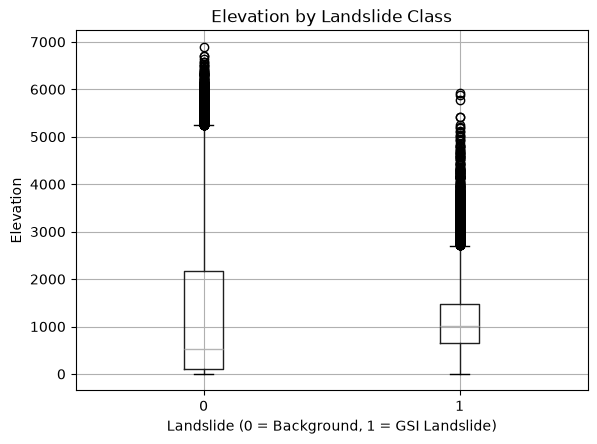

<Figure size 800x500 with 0 Axes>

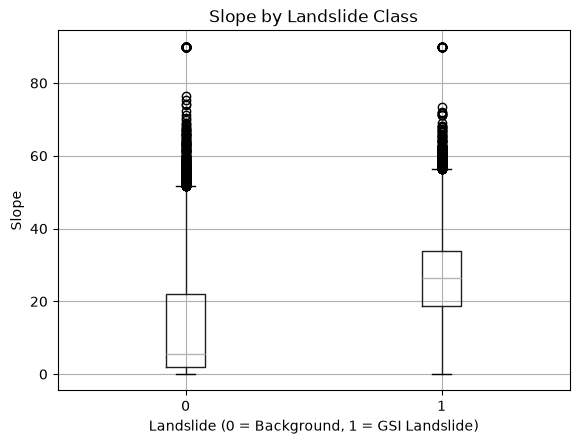

<Figure size 800x500 with 0 Axes>

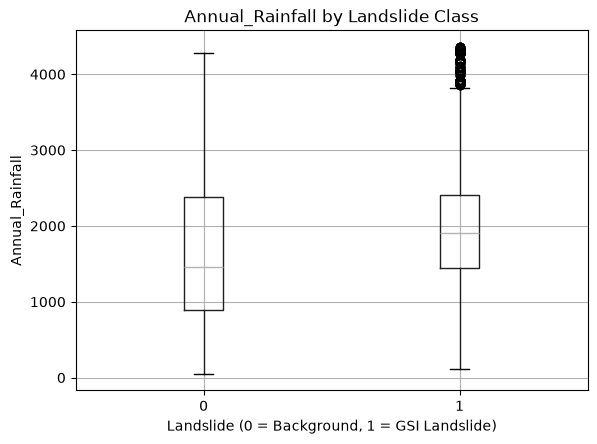

<Figure size 800x500 with 0 Axes>

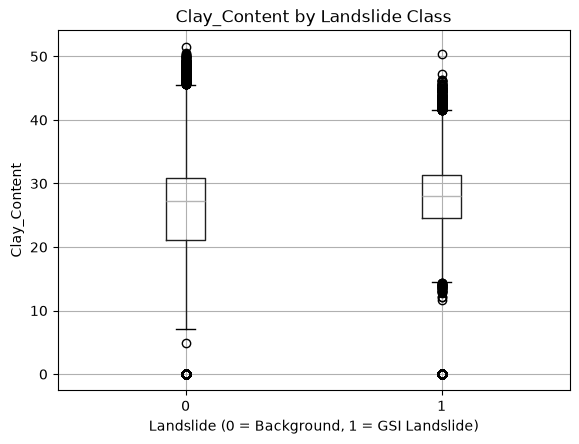

<Figure size 800x500 with 0 Axes>

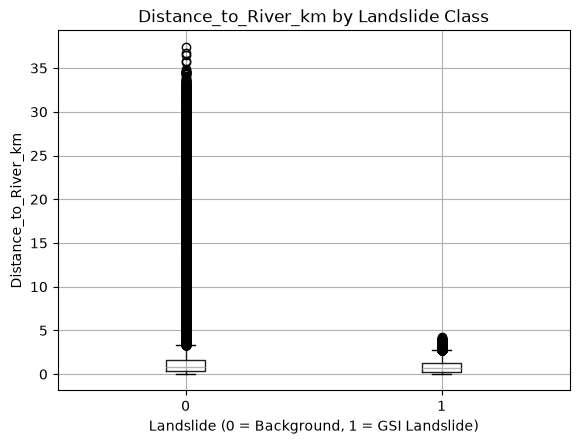

In [100]:
import matplotlib.pyplot as plt

features = [
    "Elevation",
    "Slope",
    "Annual_Rainfall",
    "Clay_Content",
    "Distance_to_River_km"
]

for feature in features:
    plt.figure(figsize=(8, 5))
    data.boxplot(column=feature, by="Landslide")
    plt.title(feature + " by Landslide Class")
    plt.suptitle("")
    plt.xlabel("Landslide (0 = Background, 1 = GSI Landslide)")
    plt.ylabel(feature)
    plt.show()

In [101]:
print(data["Land_Cover"].value_counts().sort_index())

Land_Cover
10     34890
20       723
30     10626
40      7609
50      2895
60      4887
70      1002
80      2366
90        61
95        14
100      639
Name: count, dtype: int64


In [102]:
print(
    pd.crosstab(
        data["Land_Cover"],
        data["Landslide"],
        normalize="index"
    ) * 100
)

Landslide           0          1
Land_Cover                      
10          36.021783  63.978217
20          53.526971  46.473029
30          30.312441  69.687559
40          97.095545   2.904455
50          17.962003  82.037997
60          80.028647  19.971353
70          99.600798   0.399202
80          96.027050   3.972950
90          96.721311   3.278689
95          85.714286  14.285714
100         96.557121   3.442879


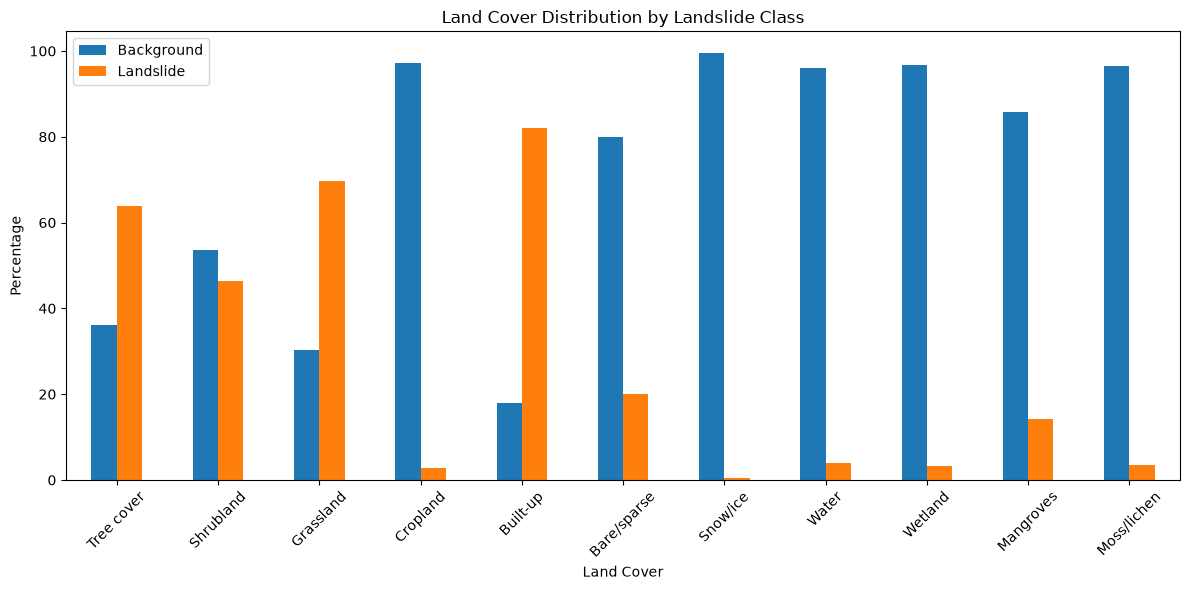

In [103]:
import matplotlib.pyplot as plt

land_cover_names = {
    10: "Tree cover",
    20: "Shrubland",
    30: "Grassland",
    40: "Cropland",
    50: "Built-up",
    60: "Bare/sparse",
    70: "Snow/ice",
    80: "Water",
    90: "Wetland",
    95: "Mangroves",
    100: "Moss/lichen"
}

land_cover_percent = (
    pd.crosstab(
        data["Land_Cover"],
        data["Landslide"],
        normalize="index"
    ) * 100
)

land_cover_percent = land_cover_percent.rename(columns={
    0: "Background",
    1: "Landslide"
})

land_cover_percent.index = [
    land_cover_names.get(x, str(x))
    for x in land_cover_percent.index
]

land_cover_percent.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Land Cover Distribution by Landslide Class")
plt.xlabel("Land Cover")
plt.ylabel("Percentage")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [104]:
import matplotlib.pyplot as plt

correlation = data[
    [
        "Elevation",
        "Slope",
        "Annual_Rainfall",
        "Clay_Content",
        "Distance_to_River_km",
        "Landslide"
    ]
].corr()

print(correlation["Landslide"].sort_values(ascending=False))

Landslide               1.000000
Slope                   0.481215
Annual_Rainfall         0.232650
Clay_Content            0.182736
Elevation              -0.117163
Distance_to_River_km   -0.165582
Name: Landslide, dtype: float64


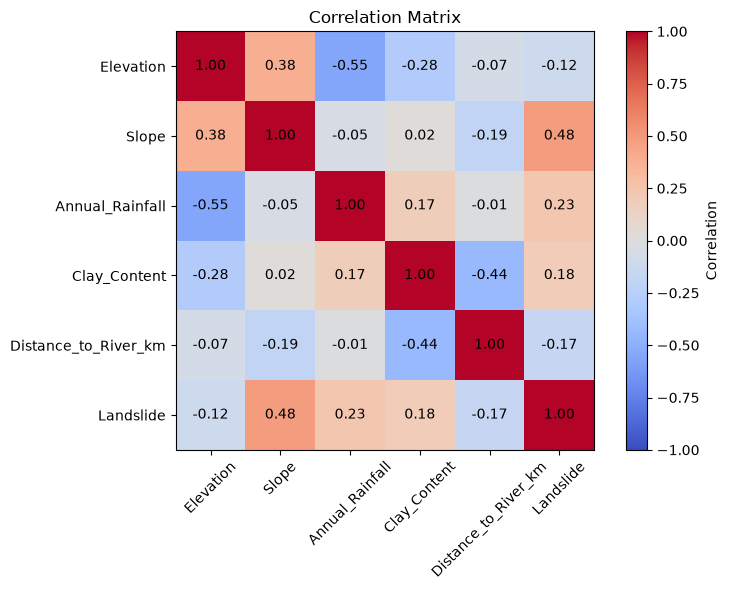

In [105]:
plt.figure(figsize=(8, 6))

plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)

plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=45)
plt.yticks(range(len(correlation.columns)), correlation.columns)

plt.colorbar(label="Correlation")
plt.title("Correlation Matrix")

for i in range(len(correlation.columns)):
    for j in range(len(correlation.columns)):
        plt.text(
            j,
            i,
            f"{correlation.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

In [106]:
from sklearn.model_selection import train_test_split

X = data[
    [
        "Elevation",
        "Slope",
        "Annual_Rainfall",
        "Land_Cover",
        "Clay_Content",
        "Distance_to_River_km"
    ]
]

y = data["Landslide"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nFeatures:")
print(X.columns.tolist())

X shape: (65712, 6)
y shape: (65712,)

Features:
['Elevation', 'Slope', 'Annual_Rainfall', 'Land_Cover', 'Clay_Content', 'Distance_to_River_km']


In [107]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 52569
Testing samples: 13143

Training class distribution:
Landslide
1    27007
0    25562
Name: count, dtype: int64

Testing class distribution:
Landslide
1    6752
0    6391
Name: count, dtype: int64


In [108]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

categorical_features = ["Land_Cover"]

numeric_features = [
    "Elevation",
    "Slope",
    "Annual_Rainfall",
    "Clay_Content",
    "Distance_to_River_km"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", "passthrough", numeric_features)
    ]
)

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [109]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.9029901848892947
Precision: 0.877359790547058
Recall: 0.9429798578199052
F1 Score: 0.9089870797344565
ROC-AUC: 0.9660818521825344

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.86      0.90      6391
           1       0.88      0.94      0.91      6752

    accuracy                           0.90     13143
   macro avg       0.91      0.90      0.90     13143
weighted avg       0.91      0.90      0.90     13143


Confusion Matrix:
[[5501  890]
 [ 385 6367]]


In [110]:
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
importances = model.named_steps["classifier"].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

print(feature_importance)


                      Feature  Importance
12                 num__Slope    0.303127
11             num__Elevation    0.237266
13       num__Annual_Rainfall    0.201539
14          num__Clay_Content    0.097182
15  num__Distance_to_River_km    0.076544
3          cat__Land_Cover_40    0.029069
0          cat__Land_Cover_10    0.016226
5          cat__Land_Cover_60    0.012340
2          cat__Land_Cover_30    0.007617
4          cat__Land_Cover_50    0.006800
7          cat__Land_Cover_80    0.006165
6          cat__Land_Cover_70    0.003509
10        cat__Land_Cover_100    0.001988
1          cat__Land_Cover_20    0.000519
8          cat__Land_Cover_90    0.000090
9          cat__Land_Cover_95    0.000018


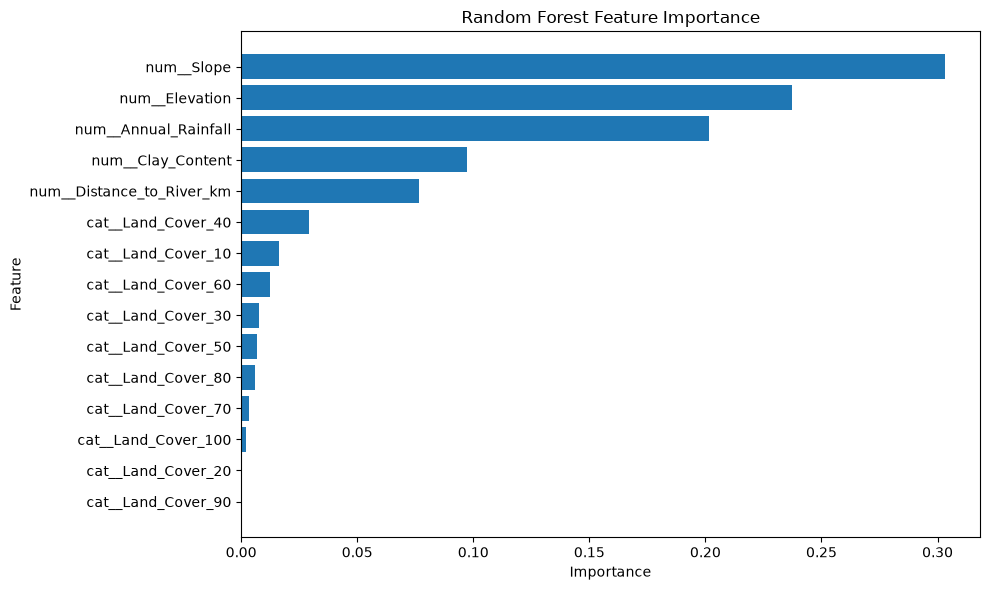

In [111]:
top_features = feature_importance.head(15)

plt.figure(figsize=(10, 6))
plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

In [112]:
data["Lat_Block"] = (data["Latitude"] // 1).astype(int)
data["Lon_Block"] = (data["Longitude"] // 1).astype(int)

data["Spatial_Block"] = (
    data["Lat_Block"].astype(str) + "_" +
    data["Lon_Block"].astype(str)
)

print("Number of spatial blocks:", data["Spatial_Block"].nunique())
print(data["Spatial_Block"].value_counts().head(10))

Number of spatial blocks: 94
Spatial_Block
27_88    2233
30_78    2031
30_77    2013
23_92    1976
31_77    1851
11_76    1708
31_76    1463
25_94    1451
33_75    1394
29_79    1345
Name: count, dtype: int64


In [113]:
from sklearn.model_selection import GroupShuffleSplit

features = [
    "Elevation",
    "Slope",
    "Annual_Rainfall",
    "Land_Cover",
    "Clay_Content",
    "Distance_to_River_km"
]

X_spatial = data[features]
y_spatial = data["Landslide"]
groups = data["Spatial_Block"]

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(X_spatial, y_spatial, groups=groups)
)

X_train_spatial = X_spatial.iloc[train_idx]
X_test_spatial = X_spatial.iloc[test_idx]

y_train_spatial = y_spatial.iloc[train_idx]
y_test_spatial = y_spatial.iloc[test_idx]

print("Training samples:", len(X_train_spatial))
print("Testing samples:", len(X_test_spatial))

print("Training spatial blocks:", data.iloc[train_idx]["Spatial_Block"].nunique())
print("Testing spatial blocks:", data.iloc[test_idx]["Spatial_Block"].nunique())

print("\nTraining class distribution:")
print(y_train_spatial.value_counts())

print("\nTesting class distribution:")
print(y_test_spatial.value_counts())

Training samples: 50847
Testing samples: 14865
Training spatial blocks: 75
Testing spatial blocks: 19

Training class distribution:
Landslide
0    25960
1    24887
Name: count, dtype: int64

Testing class distribution:
Landslide
1    8872
0    5993
Name: count, dtype: int64


In [114]:
spatial_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

spatial_model.fit(X_train_spatial, y_train_spatial)

print("Spatial Random Forest training completed.")

Spatial Random Forest training completed.


In [115]:
y_pred_spatial = spatial_model.predict(X_test_spatial)
y_prob_spatial = spatial_model.predict_proba(X_test_spatial)[:, 1]

print("Accuracy:", accuracy_score(y_test_spatial, y_pred_spatial))
print("Precision:", precision_score(y_test_spatial, y_pred_spatial))
print("Recall:", recall_score(y_test_spatial, y_pred_spatial))
print("F1 Score:", f1_score(y_test_spatial, y_pred_spatial))
print("ROC-AUC:", roc_auc_score(y_test_spatial, y_prob_spatial))

print("\nClassification Report:")
print(classification_report(y_test_spatial, y_pred_spatial))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_spatial, y_pred_spatial))

Accuracy: 0.8807265388496468
Precision: 0.9010281324144165
Recall: 0.8988954012623985
F1 Score: 0.8999605033007956
ROC-AUC: 0.9414303349399067

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.85      0.85      5993
           1       0.90      0.90      0.90      8872

    accuracy                           0.88     14865
   macro avg       0.88      0.88      0.88     14865
weighted avg       0.88      0.88      0.88     14865


Confusion Matrix:
[[5117  876]
 [ 897 7975]]


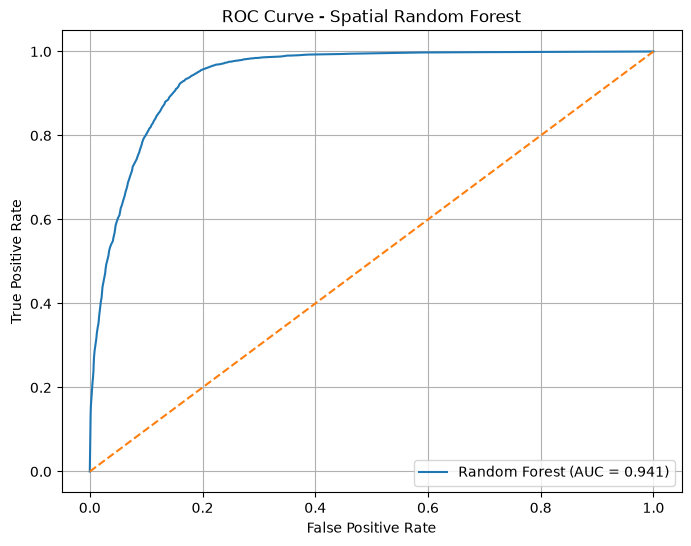

In [116]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(
    y_test_spatial,
    y_prob_spatial
)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {roc_auc_score(y_test_spatial, y_prob_spatial):.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Spatial Random Forest")
plt.legend()
plt.grid()
plt.show()

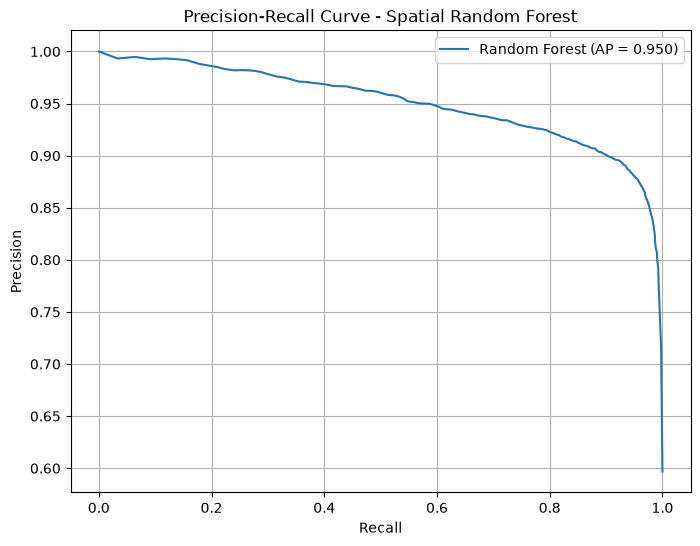

Average Precision: 0.9499002458384133


In [117]:
from sklearn.metrics import precision_recall_curve, average_precision_score

precision, recall, thresholds = precision_recall_curve(
    y_test_spatial,
    y_prob_spatial
)

average_precision = average_precision_score(
    y_test_spatial,
    y_prob_spatial
)

plt.figure(figsize=(8, 6))
plt.plot(
    recall,
    precision,
    label=f"Random Forest (AP = {average_precision:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Spatial Random Forest")
plt.legend()
plt.grid()
plt.show()

print("Average Precision:", average_precision)

In [118]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_test_spatial,
    y_prob_spatial
)

f1_scores = 2 * (precision[:-1] * recall[:-1]) / (
    precision[:-1] + recall[:-1] + 1e-10
)

best_index = f1_scores.argmax()

best_threshold = thresholds[best_index]
best_f1 = f1_scores[best_index]

print("Best threshold:", best_threshold)
print("Best F1 Score:", best_f1)
print("Precision at best threshold:", precision[best_index])
print("Recall at best threshold:", recall[best_index])

Best threshold: 0.35
Best F1 Score: 0.9149636019991632
Precision at best threshold: 0.8770805334436059
Recall at best threshold: 0.9562669071235347


In [119]:
from sklearn.metrics import precision_score, recall_score, f1_score

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    predictions = (y_prob_spatial >= threshold).astype(int)

    precision_value = precision_score(
        y_test_spatial,
        predictions
    )

    recall_value = recall_score(
        y_test_spatial,
        predictions
    )

    f1_value = f1_score(
        y_test_spatial,
        predictions
    )

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision_value:.3f} | "
        f"Recall: {recall_value:.3f} | "
        f"F1: {f1_value:.3f}"
    )

Threshold: 0.30 | Precision: 0.868 | Recall: 0.966 | F1: 0.914
Threshold: 0.35 | Precision: 0.877 | Recall: 0.956 | F1: 0.915
Threshold: 0.40 | Precision: 0.884 | Recall: 0.944 | F1: 0.913
Threshold: 0.45 | Precision: 0.893 | Recall: 0.927 | F1: 0.910
Threshold: 0.50 | Precision: 0.900 | Recall: 0.901 | F1: 0.901
Threshold: 0.55 | Precision: 0.907 | Recall: 0.875 | F1: 0.891
Threshold: 0.60 | Precision: 0.915 | Recall: 0.839 | F1: 0.875


In [120]:
import joblib

joblib.dump(spatial_model, "landslide_random_forest.pkl")

print("Model saved successfully.")

Model saved successfully.


In [121]:
import os

print("Model exists:", os.path.exists("landslide_random_forest.pkl"))
print("Model size:", round(os.path.getsize("landslide_random_forest.pkl") / (1024 * 1024), 2), "MB")

Model exists: True
Model size: 142.31 MB


In [122]:
import joblib

joblib.dump(spatial_model, "landslide_random_forest.pkl")

print("Model saved successfully.")

Model saved successfully.


In [123]:
import os

print("Model exists:", os.path.exists("landslide_random_forest.pkl"))
print(
    "Model size:",
    round(os.path.getsize("landslide_random_forest.pkl") / (1024 * 1024), 2),
    "MB"
)

Model exists: True
Model size: 142.31 MB


In [124]:
%pip install streamlit folium streamlit-folium

Note: you may need to restart the kernel to use updated packages.


In [125]:
sample = X_test_spatial.iloc[[0]]

probability = spatial_model.predict_proba(sample)[0][1]

print("Landslide Probability:", round(probability * 100, 2), "%")
print("\nLocation:")
print("Latitude:", data.loc[sample.index[0], "Latitude"])
print("Longitude:", data.loc[sample.index[0], "Longitude"])

Landslide Probability: 2.5 %

Location:
Latitude: 25.855233933282847
Longitude: 92.9204619784452


In [126]:
import requests

API_KEY = "YOUR_API_KEY_HERE"

def get_elevation(latitude, longitude):
    url = "https://portal.opentopography.org/API/v1/elevation"

    params = {
        "latitude": latitude,
        "longitude": longitude,
        "dataset": "SRTM_GL1",
        "API_Key": API_KEY
    }

    response = requests.get(url, params=params)

    if response.status_code != 200:
        print("Error:", response.status_code)
        print(response.text)
        return None

    data = response.json()
    return data["elevation"]

In [127]:
%pip install requests

Note: you may need to restart the kernel to use updated packages.


In [128]:
import requests

def get_elevation(latitude, longitude):
    url = "https://api.open-meteo.com/v1/elevation"

    params = {
        "latitude": latitude,
        "longitude": longitude
    }

    response = requests.get(url, params=params)

    if response.status_code != 200:
        print("Error:", response.status_code)
        print(response.text)
        return None

    data = response.json()
    return data["elevation"][0]

In [129]:
latitude = 13.36833
longitude = 77.68270

elevation = get_elevation(latitude, longitude)

print("Latitude:", latitude)
print("Longitude:", longitude)
print("Elevation:", elevation, "m")

Latitude: 13.36833
Longitude: 77.6827
Elevation: 1440.0 m


In [130]:
import requests
import math

def get_slope(latitude, longitude):
    delta = 0.001

    latitudes = [
        latitude - delta,
        latitude,
        latitude + delta
    ]

    longitudes = [
        longitude - delta,
        longitude,
        longitude + delta
    ]

    points = []

    for lat in latitudes:
        for lon in longitudes:
            points.append((lat, lon))

    url = "https://api.open-meteo.com/v1/elevation"

    params = {
        "latitude": ",".join(str(p[0]) for p in points),
        "longitude": ",".join(str(p[1]) for p in points)
    }

    response = requests.get(url, params=params)

    if response.status_code != 200:
        print("Error:", response.status_code)
        return None

    elevations = response.json()["elevation"]

    elevation = [
        elevations[0:3],
        elevations[3:6],
        elevations[6:9]
    ]

    dx = 111320 * math.cos(math.radians(latitude)) * delta
    dy = 111320 * delta

    dz_dx = (elevation[1][2] - elevation[1][0]) / (2 * dx)
    dz_dy = (elevation[2][1] - elevation[0][1]) / (2 * dy)

    slope = math.degrees(
        math.atan(math.sqrt(dz_dx**2 + dz_dy**2))
    )

    return slope

In [131]:
slope = get_slope(latitude, longitude)

print("Slope:", round(slope, 2), "degrees")

Slope: 15.37 degrees


In [132]:
def get_rainfall(latitude, longitude):
    url = "https://power.larc.nasa.gov/api/temporal/climatology/point"

    params = {
        "parameters": "PRECTOTCORR",
        "community": "AG",
        "longitude": longitude,
        "latitude": latitude,
        "format": "JSON"
    }

    response = requests.get(url, params=params)

    if response.status_code != 200:
        print("Error:", response.status_code)
        print(response.text)
        return None

    data = response.json()

    values = data["properties"]["parameter"]["PRECTOTCORR"]

    days = {
        "JAN": 31,
        "FEB": 28,
        "MAR": 31,
        "APR": 30,
        "MAY": 31,
        "JUN": 30,
        "JUL": 31,
        "AUG": 31,
        "SEP": 30,
        "OCT": 31,
        "NOV": 30,
        "DEC": 31
    }

    annual_rainfall = 0

    for month in days:
        annual_rainfall += values[month] * days[month]

    return annual_rainfall

In [133]:
rainfall = get_rainfall(latitude, longitude)

print("Annual Rainfall:", round(rainfall, 2), "mm")

Annual Rainfall: 799.97 mm


In [134]:
import rasterio
import math

def get_land_cover(latitude, longitude):

    lat_start = math.floor(latitude / 3) * 3
    lon_start = math.floor(longitude / 3) * 3

    lat_name = f"N{lat_start:02d}" if lat_start >= 0 else f"S{abs(lat_start):02d}"
    lon_name = f"E{lon_start:03d}" if lon_start >= 0 else f"W{abs(lon_start):03d}"

    filename = f"ESA_WorldCover_10m_2021_v200_{lat_name}{lon_name}_Map.tif"

    url = (
        "https://esa-worldcover.s3.eu-central-1.amazonaws.com/"
        f"v200/2021/map/{filename}"
    )

    try:
        with rasterio.Env(AWS_NO_SIGN_REQUEST="YES"):
            with rasterio.open(url) as src:
                value = list(src.sample([(longitude, latitude)]))[0][0]

        return int(value)

    except Exception as e:
        print("Error:", e)
        return None

In [135]:
land_cover = get_land_cover(latitude, longitude)

print("Land Cover:", land_cover)

Land Cover: 50


In [136]:
%pip install owslib

Note: you may need to restart the kernel to use updated packages.


In [137]:
def get_clay(latitude, longitude):
    url = "https://maps.isric.org/mapserv?map=/map/clay.map"

    params = [
        ("SERVICE", "WCS"),
        ("VERSION", "2.0.1"),
        ("REQUEST", "GetCoverage"),
        ("COVERAGEID", "clay_0-5cm_mean"),
        ("FORMAT", "GEOTIFF_INT16"),
        ("SUBSETTINGCRS", "http://www.opengis.net/def/crs/EPSG/0/4326"),
        ("OUTPUTCRS", "http://www.opengis.net/def/crs/EPSG/0/4326"),
        ("SUBSET", f"X({longitude-0.002},{longitude+0.002})"),
        ("SUBSET", f"Y({latitude-0.002},{latitude+0.002})")
    ]

    response = requests.get(url, params=params)

    if response.status_code != 200:
        print("Error:", response.status_code)
        print(response.text)
        return None

    with rasterio.open(io.BytesIO(response.content)) as src:
        value = list(src.sample([(longitude, latitude)]))[0][0]

    return float(value) / 10

In [139]:
import io

In [140]:
clay = get_clay(latitude, longitude)

print("Clay Content:", round(clay, 2), "%")

Clay Content: 24.0 %


In [141]:
import geopandas as gpd
from shapely.geometry import Point

def get_river_distance(latitude, longitude):

    point = gpd.GeoDataFrame(
        geometry=[Point(longitude, latitude)],
        crs="EPSG:4326"
    )

    zone = int((longitude + 180) / 6) + 1
    epsg = 32600 + zone

    point_utm = point.to_crs(epsg)

    nearest_index = rivers.sindex.nearest(
        Point(longitude, latitude)
    )

    river = rivers.iloc[nearest_index[1][0]]

    river_gdf = gpd.GeoDataFrame(
        [river],
        geometry="geometry",
        crs="EPSG:4326"
    )

    river_utm = river_gdf.to_crs(epsg)

    distance_m = point_utm.geometry.iloc[0].distance(
        river_utm.geometry.iloc[0]
    )

    return distance_m / 1000

In [142]:
import geopandas as gpd

rivers = gpd.read_file(
    r"C:\Users\workr\landslide Data\river data\HydroRIVERS\HydroRIVERS_v10_as_shp\HydroRIVERS_v10_as.shp",
    engine="pyogrio"
)

print("River segments:", len(rivers))
print("CRS:", rivers.crs)

River segments: 1428959
CRS: EPSG:4326


In [143]:
river_distance = get_river_distance(latitude, longitude)

print(
    "Distance to River:",
    round(river_distance, 3),
    "km"
)

Distance to River: 3.309 km


In [144]:
import pandas as pd

In [145]:
location_features = pd.DataFrame([{
    "Elevation": elevation,
    "Slope": slope,
    "Annual_Rainfall": rainfall,
    "Land_Cover": land_cover,
    "Clay_Content": clay,
    "Distance_to_River_km": river_distance
}])

location_features

,Elevation,Slope,Annual_Rainfall,Land_Cover,Clay_Content,Distance_to_River_km
0,1440.0,15.368253,799.97,50,24.0,3.309037


In [146]:
import joblib

spatial_model = joblib.load("landslide_random_forest.pkl")

In [147]:
print(spatial_model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Land_Cover']),
                                                 ('num', 'passthrough',
                                                  ['Elevation', 'Slope',
                                                   'Annual_Rainfall',
                                                   'Clay_Content',
                                                   'Distance_to_River_km'])])),
                ('classifier',
                 RandomForestClassifier(n_estimators=200, n_jobs=-1,
                                        random_state=42))])


In [148]:
probability = spatial_model.predict_proba(location_features)[0][1]

print("Landslide Probability:", round(probability * 100, 2), "%")

Landslide Probability: 52.5 %


In [149]:
import pandas as pd
import joblib

spatial_model = joblib.load("landslide_random_forest.pkl")

def predict_location(latitude, longitude):

    elevation = get_elevation(latitude, longitude)
    slope = get_slope(latitude, longitude)
    rainfall = get_rainfall(latitude, longitude)
    land_cover = get_land_cover(latitude, longitude)
    clay = get_clay(latitude, longitude)
    river_distance = get_river_distance(latitude, longitude)

    features = pd.DataFrame([{
        "Elevation": elevation,
        "Slope": slope,
        "Annual_Rainfall": rainfall,
        "Land_Cover": land_cover,
        "Clay_Content": clay,
        "Distance_to_River_km": river_distance
    }])

    probability = spatial_model.predict_proba(features)[0][1] * 100

    print("Latitude:", latitude)
    print("Longitude:", longitude)
    print()
    print("Elevation:", round(elevation, 2), "m")
    print("Slope:", round(slope, 2), "degrees")
    print("Annual Rainfall:", round(rainfall, 2), "mm")
    print("Land Cover:", land_cover)
    print("Clay Content:", round(clay, 2), "%")
    print("Distance to River:", round(river_distance, 3), "km")
    print()
    print("Landslide Susceptibility:", round(probability, 2), "%")

    return probability

In [150]:
predict_location(13.36833, 77.68270)

Latitude: 13.36833
Longitude: 77.6827

Elevation: 1440.0 m
Slope: 15.37 degrees
Annual Rainfall: 799.97 mm
Land Cover: 50
Clay Content: 24.0 %
Distance to River: 3.309 km

Landslide Susceptibility: 52.5 %


np.float64(52.5)

In [151]:
predict_location(30.3165, 78.0322)

Latitude: 30.3165
Longitude: 78.0322

Elevation: 652.0 m
Slope: 1.32 degrees
Annual Rainfall: 1294.45 mm
Land Cover: 50
Clay Content: 0.0 %
Distance to River: 0.865 km

Landslide Susceptibility: 2.5 %


np.float64(2.5)

In [152]:
predict_location(28.6139, 77.2090)

Latitude: 28.6139
Longitude: 77.209

Elevation: 214.0 m
Slope: 1.2 degrees
Annual Rainfall: 751.02 mm
Land Cover: 50
Clay Content: 0.0 %
Distance to River: 1.567 km

Landslide Susceptibility: 0.0 %


np.float64(0.0)

In [153]:
predict_location(28.449572, 77.584866)

Latitude: 28.449572
Longitude: 77.584866

Elevation: 207.0 m
Slope: 0.39 degrees
Annual Rainfall: 751.02 mm
Land Cover: 50
Clay Content: 26.2 %
Distance to River: 0.784 km

Landslide Susceptibility: 1.5 %


np.float64(1.5)

In [154]:
predict_location(32.37139, 77.24639)

Latitude: 32.37139
Longitude: 77.24639

Elevation: 3995.0 m
Slope: 20.07 degrees
Annual Rainfall: 676.71 mm
Land Cover: 100
Clay Content: 21.2 %
Distance to River: 2.013 km

Landslide Susceptibility: 9.5 %


np.float64(9.5)

In [156]:
predict_location(27.42, 88.59)

Latitude: 27.42
Longitude: 88.59

Elevation: 1537.0 m
Slope: 19.09 degrees
Annual Rainfall: 1092.01 mm
Land Cover: 10
Clay Content: 28.2 %
Distance to River: 0.492 km

Landslide Susceptibility: 54.5 %


np.float64(54.50000000000001)

In [157]:
import os
import glob

rainfall_folder = r"C:\Users\workr\landslide Data\rainfall data"

rainfall_files = glob.glob(
    os.path.join(
        rainfall_folder,
        "IMERG-Final.CLIM.200006-202305.V07B*.tif"
    )
)

print(rainfall_files)

['C:\\Users\\workr\\landslide Data\\rainfall data\\IMERG-Final.CLIM.200006-202305.V07B.tif']


In [158]:
import rasterio

rainfall_file = rainfall_files[0]

def get_rainfall(latitude, longitude):

    with rasterio.open(rainfall_file) as src:

        value = list(
            src.sample([(longitude, latitude)])
        )[0][0]

        if src.nodata is not None and value == src.nodata:
            return None

    return float(value)

In [159]:
rainfall = get_rainfall(13.36833, 77.68270)

print("Annual Rainfall:", round(rainfall, 2), "mm")

Annual Rainfall: 884.45 mm


In [160]:
rainfall = get_rainfall(32.37139, 77.24639)

print("Annual Rainfall:", round(rainfall, 2), "mm")

Annual Rainfall: 683.98 mm


In [161]:
predict_location(24.6467, 72.7786)

Latitude: 24.6467
Longitude: 72.7786

Elevation: 1608.0 m
Slope: 27.76 degrees
Annual Rainfall: 728.76 mm
Land Cover: 20
Clay Content: 35.9 %
Distance to River: 4.101 km

Landslide Susceptibility: 33.0 %


np.float64(33.0)

In [162]:
predict_location(32.37139, 77.24639)

Latitude: 32.37139
Longitude: 77.24639

Elevation: 3995.0 m
Slope: 20.07 degrees
Annual Rainfall: 683.98 mm
Land Cover: 100
Clay Content: 21.2 %
Distance to River: 2.013 km

Landslide Susceptibility: 20.0 %


np.float64(20.0)

In [163]:
predict_location(30.284414, 78.981140)

Latitude: 30.284414
Longitude: 78.98114

Elevation: 697.0 m
Slope: 10.37 degrees
Annual Rainfall: 1604.03 mm
Land Cover: 50
Clay Content: 27.4 %
Distance to River: 0.222 km

Landslide Susceptibility: 94.5 %


np.float64(94.5)

In [164]:
joblib.dump(spatial_model, "landslide_random_forest.pkl")

['landslide_random_forest.pkl']